In [1]:
import pandas as pd

# 从CSV文件读取数据
data = pd.read_csv('processed_data.csv')
data.head()

,Unnamed: 0,material,stroke,osc_freq,force,cycle,coe,Absolute_Energy,Amplitude,ASL,Average_Frequency,Initiation_Frequency,Parametric_1,Parametric_2,Peak_Frequency,Reverberation_Frequency,Threshold,stage
0,0,steel-glass,100,5,5,1,0.021518,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,stage1
1,1,steel-glass,100,5,5,2,0.009959,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,stage1
2,2,steel-glass,100,5,5,3,0.021819,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,stage1
3,3,steel-glass,100,5,5,4,0.019355,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,stage1
4,4,steel-glass,100,5,5,5,0.012795,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,stage1


In [2]:
# features and labels
X = data[['coe', 'Absolute_Energy', 'Amplitude', 'ASL', 'Average_Frequency', 'Initiation_Frequency', 'Parametric_1', 'Parametric_2', 'Peak_Frequency', 'Reverberation_Frequency']]
y = data['stage']

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
from sklearn.ensemble import RandomForestClassifier

# 初始化模型（可调整参数）
model = RandomForestClassifier(
    n_estimators=100,  # 树的数量
    max_depth=5,       # 树的最大深度（防止过拟合）
    random_state=42
)

# 训练模型
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

In [5]:
from sklearn.metrics import accuracy_score, classification_report

# 预测测试集
y_pred = model.predict(X_test)

# 评估性能
print("准确率:", accuracy_score(y_test, y_pred))
print("分类报告:\n", classification_report(y_test, y_pred))

# 查看特征重要性
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)
print("特征重要性:\n", feature_importance)

准确率: 0.914572864321608
分类报告:
               precision    recall  f1-score   support

      stage1       1.00      1.00      1.00        67
      stage2       0.86      0.89      0.87        27
      stage3       0.50      0.38      0.43        16
      stage4       0.92      0.96      0.94        89

    accuracy                           0.91       199
   macro avg       0.82      0.80      0.81       199
weighted avg       0.91      0.91      0.91       199

特征重要性:
                    feature  importance
7             Parametric_2    0.262374
8           Peak_Frequency    0.156268
6             Parametric_1    0.098512
3                      ASL    0.096967
1          Absolute_Energy    0.092837
9  Reverberation_Frequency    0.084140
4        Average_Frequency    0.076631
5     Initiation_Frequency    0.062453
2                Amplitude    0.058649
0                      coe    0.011167


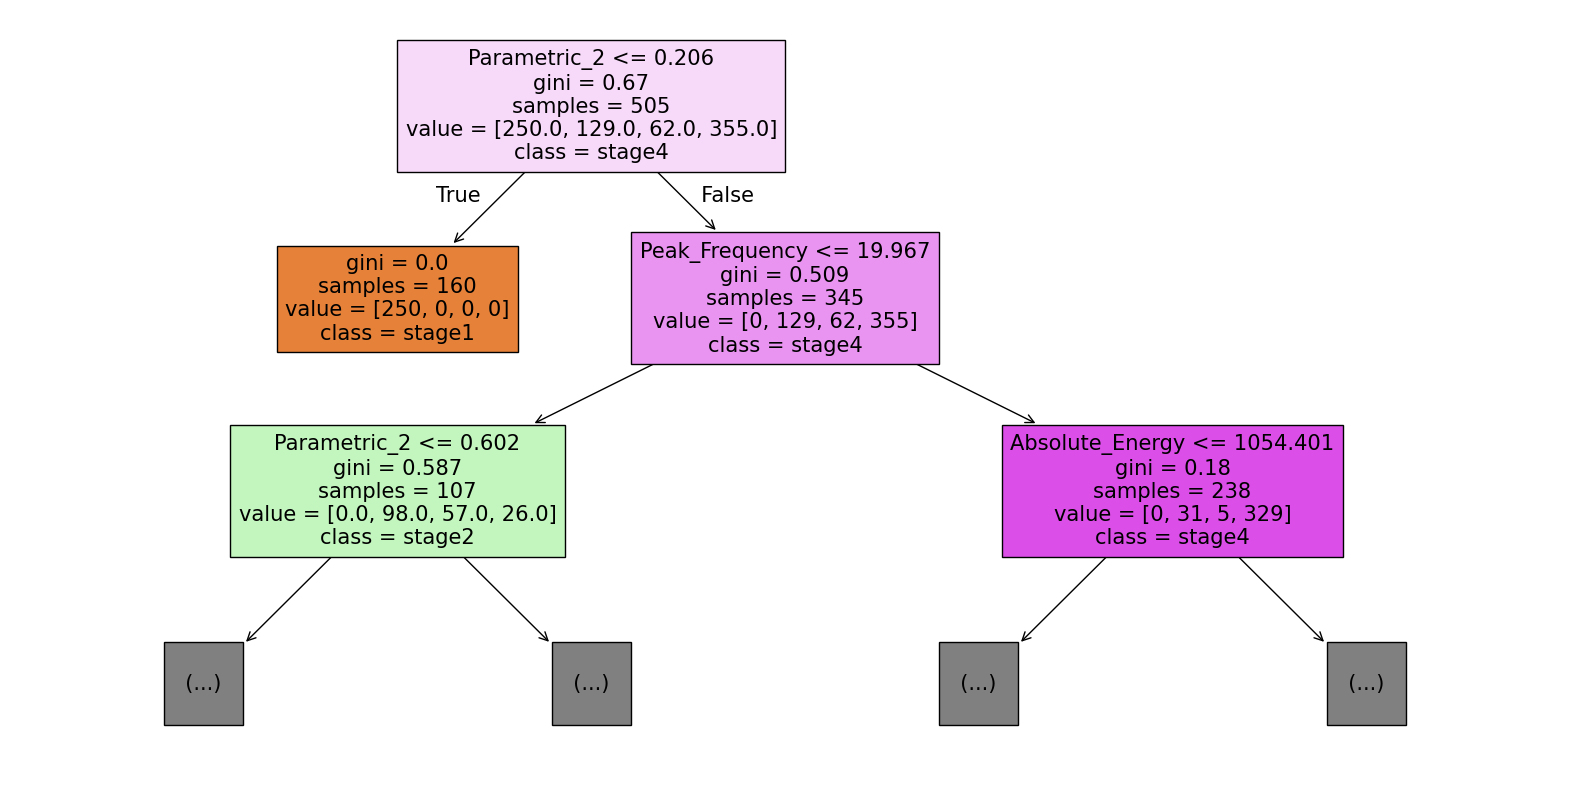

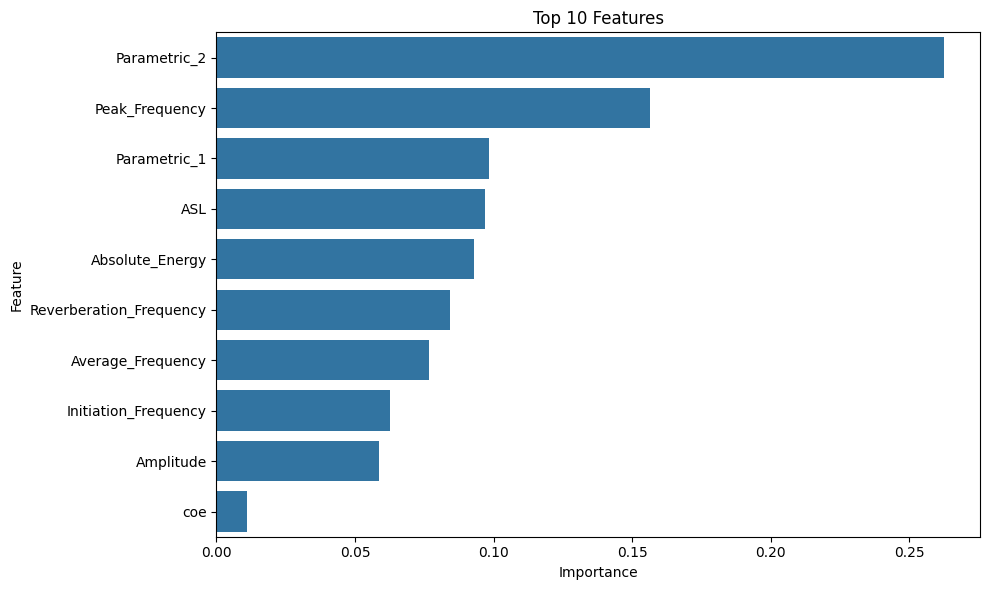

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import seaborn as sns

# 1. 绘制第一棵树
plt.figure(figsize=(20, 10))
plot_tree(model.estimators_[0], 
          feature_names=X_train.columns,
          class_names=['stage1', 'stage2', 'stage3', 'stage4'],
          filled=True, max_depth=2)
plt.show()

# 2. 绘制特征重要性
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Top 10 Features')
plt.tight_layout()
plt.show()